# Ejercicio 1.1 · primer buscador semántico

Buscador semántico mínimo con `sentence-transformers` + `numpy`, sin base vectorial. Objetivo: entender qué hace exactamente un embedding.

## 1. Dependencias

Las librerías que usamos se instalan con `uv` (nunca con `pip`). Ya están declaradas en `pyproject.toml`, así que normalmente no hace falta ejecutar nada. Si falta alguna:

```bash
uv add sentence-transformers numpy scikit-learn matplotlib
```

- `sentence-transformers`: carga el modelo que convierte texto en vectores.
- `numpy`: operaciones con matrices (para calcular similitudes).
- `scikit-learn`: trae t-SNE, que usamos en el Bonus 2.
- `matplotlib`: para dibujar el gráfico del Bonus 2.

In [1]:
# Importamos las librerías que vamos a usar
import numpy as np                                  # matrices y cálculos
import matplotlib.pyplot as plt                     # gráficos (Bonus 2)
from sentence_transformers import SentenceTransformer  # modelo de embeddings
from sklearn.manifold import TSNE                   # reducir a 2D (Bonus 2)

W1116 12:05:51.106000 48666 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## 2. Corpus (24 frases, 4 temas)

El corpus es nuestra "base de conocimiento": 24 frases cortas repartidas en 4 temas (6 por tema). Las guardamos en un diccionario `{tema: [frases]}` y con dos bucles `for` las pasamos a dos listas paralelas:

- `corpus`: todas las frases.
- `temas`: el tema de cada frase, en el mismo orden (`corpus[5]` y `temas[5]` van juntas).

El buscador solo usa `corpus`. La lista `temas` la usamos para mostrar resultados y en los bonus.

In [2]:
corpus_por_tema = {
    "tecnología": [
        "Los modelos de lenguaje generan texto prediciendo la siguiente palabra.",
        "Python es un lenguaje de programación muy popular para ciencia de datos.",
        "La computación en la nube permite escalar servidores bajo demanda.",
        "Un algoritmo de cifrado protege los datos que viajan por internet.",
        "Los teléfonos inteligentes incorporan cámaras cada vez más potentes.",
        "Las bases de datos vectoriales almacenan representaciones numéricas de textos.",
    ],
    "deportes": [
        "El delantero marcó dos goles en el último minuto del partido.",
        "La maratonista batió el récord mundial en menos de dos horas y diez minutos.",
        "El equipo de baloncesto ganó el campeonato tras una final muy igualada.",
        "La tenista ganó el torneo sin ceder ni un solo set.",
        "Entrenar la resistencia mejora el rendimiento de los ciclistas en montaña.",
        "El portero detuvo un penalti decisivo en la tanda final.",
    ],
    "cocina": [
        "Para hacer una buena tortilla de patatas hay que pochar las patatas despacio.",
        "El arroz se cocina con el doble de agua y se deja reposar tapado.",
        "La masa de pizza necesita reposar varias horas para fermentar.",
        "Sofríe la cebolla y el ajo antes de añadir el tomate triturado.",
        "El chocolate negro se derrite al baño maría sin que se queme.",
        "Un buen caldo de pollo se prepara cociendo huesos y verduras a fuego lento.",
    ],
    "historia": [
        "El Imperio romano dominó el Mediterráneo durante siglos.",
        "La Revolución francesa derribó la monarquía absoluta en 1789.",
        "Cristóbal Colón llegó a América en 1492 financiado por los Reyes Católicos.",
        "La caída del Muro de Berlín en 1989 simbolizó el fin de la Guerra Fría.",
        "Los egipcios construyeron las pirámides como tumbas para sus faraones.",
        "La Revolución industrial transformó la economía y las ciudades europeas.",
    ],
}
corpus = []  # todas las frases, una detrás de otra
temas = []   # el tema de cada frase, en el mismo orden

for tema, frases in corpus_por_tema.items():
    for frase in frases:
        corpus.append(frase)
        temas.append(tema)

print(len(corpus), "frases")

24 frases


## 3. Modelo de embeddings

**¿Qué son los "pesos" (weights)?** Un modelo es una red neuronal: una cadena enorme de operaciones matemáticas. Cada operación usa números ajustables, y esos números son los *pesos*. Durante el entrenamiento (hecho por otros, con millones de frases) el modelo ajustó sus pesos hasta aprender que "perro" y "can" significan algo parecido. Los pesos son todo lo que el modelo "sabe".

- **Entrenar** = ajustar los pesos (ya está hecho, no lo hacemos nosotros).
- **Cargar el modelo** = leer los pesos del disco y ponerlos en memoria (lo que hace la barra `Loading weights`).
- **Usar el modelo** (`model.encode`) = pasar un texto por esos pesos para obtener su vector. Los pesos no cambian al usarlo.

La barra `199/199` indica que se han cargado los 199 bloques de pesos de este modelo. La primera vez se descargan de internet (~470 MB) y quedan en caché.

In [3]:
model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

## 4. Embeddings de todo el corpus

`model.encode(corpus)` pasa **cada frase** por los pesos del modelo y devuelve un **vector** (una lista de 384 números) por frase. Todos los vectores juntos forman una matriz de NumPy: `corpus_emb`.

`corpus_emb.shape` es `(24, 384)`:

| Número | Significado |
|---|---|
| **24** | filas: una por cada frase del corpus |
| **384** | columnas: los números que describen cada frase |

```
frase 0  → [0.12, -0.53, 0.08, ... 384 números]
frase 1  → [-0.31, 0.22, 0.91, ... 384 números]
...
frase 23 → [0.05, 0.47, -0.19, ... 384 números]
```

**¿Qué es cada vector?** La "huella de significado" de la frase. Los 384 números por separado no se pueden interpretar, pero juntos colocan la frase en un mapa de 384 dimensiones: frases con significado parecido quedan en puntos cercanos.

Esta matriz es nuestro "índice". En el paso 5, la query también se convertirá en un vector de 384 números y se comparará con cada una de las 24 filas.

### ¿Dónde guardamos los vectores? Sin base vectorial

En este ejercicio **no usamos ninguna base vectorial**. Los vectores viven solo en memoria, en una matriz de NumPy (`corpus_emb`):

- No hay base de datos, ni archivo, ni servidor.
- Si cierras el notebook o reinicias el kernel, la matriz se pierde y hay que volver a calcularla.
- La búsqueda compara la query con **las 24 filas una por una**.

Con 24 frases esto es instantáneo. Con un millón de documentos sería lento y no cabría cómodamente en memoria. Una base vectorial (como `chromadb`, FAISS, Qdrant, Pinecone o pgvector) resuelve tres cosas:

| Problema | Qué hace la base vectorial |
|---|---|
| **Persistencia** | Guarda los vectores en disco, no hay que recalcularlos |
| **Velocidad** | Usa índices aproximados (ANN) para no comparar con todos los vectores |
| **Metadatos** | Permite filtrar (por tema, fecha, autor) junto con la búsqueda |

La idea es la misma que hacemos aquí a mano: guardar vectores y buscar los más parecidos. Lo construimos primero con NumPy para entender qué hay debajo; las bases vectoriales llegarán en las siguientes lecciones.

In [4]:
corpus_emb = model.encode(corpus)
print(corpus_emb.shape)  # (n_frases, dimensiones)

(24, 384)


## 5. Función de búsqueda

`buscar(query, k)` hace 4 pasos:

1. Convierte la query en un vector con el mismo modelo.
2. Calcula la similitud con las 24 frases del corpus.
3. Ordena de más parecida a menos parecida.
4. Muestra las `k` mejores (por defecto 3).

### Producto escalar

Es una operación entre dos vectores que da **un solo número**: se multiplican los números de las mismas posiciones y se suma todo.

```python
a = [1, 2, 3]
b = [4, 5, 6]

# 1*4 + 2*5 + 3*6 = 4 + 10 + 18 = 32
```

Con un bucle `for` se ve claro:

```python
resultado = 0
for i in range(len(a)):
    resultado = resultado + a[i] * b[i]
print(resultado)  # 32
```

**¿Qué mide?** Cuánto "apuntan en la misma dirección" dos vectores:

- número alto → se parecen
- cerca de 0 → no tienen relación
- negativo → son opuestos

### Similitud coseno

Mide el **ángulo** entre dos vectores y va de -1 a 1. Cuanto más cerca de 1, más se parecen en significado. Si los vectores están **normalizados** (longitud 1), el producto escalar es exactamente la similitud coseno. Por eso la función `normalizar` deja cada vector con longitud 1: así basta con el producto escalar.

Ejemplo con vectores de solo 2 números, ya normalizados:

| Vector A | Vector B | Producto escalar | Significado |
|---|---|---|---|
| [1, 0] | [1, 0] | 1.0 | idénticos |
| [1, 0] | [0.6, 0.8] | 0.6 | parecidos |
| [1, 0] | [0, 1] | 0.0 | sin relación |
| [1, 0] | [-1, 0] | -1.0 | opuestos |

Los embeddings funcionan igual, solo que con 384 números en lugar de 2.

### El operador `@`

`@` es el operador de NumPy para multiplicar matrices. Cuando un lado es una matriz y el otro un vector, hace el producto escalar del vector con **cada fila** de la matriz:

```python
similitudes = corpus_norm @ query_norm
```

| Variable | Forma | Significado |
|---|---|---|
| `corpus_norm` | (24, 384) | una fila por frase |
| `query_norm` | (384,) | el vector de la query |
| `similitudes` | (24,) | un número por frase |

Es equivalente a este bucle (más lento y más largo, pero hace lo mismo):

```python
similitudes = []
for fila in corpus_norm:
    similitud = np.dot(fila, query_norm)  # producto escalar de una frase con la query
    similitudes.append(similitud)
```

### Ordenar los resultados

`np.argsort(similitudes)` no devuelve las similitudes ordenadas, sino las **posiciones** (índices) de las frases ordenadas de menor a mayor similitud. Con `[::-1]` se le da la vuelta para tener primero las más parecidas, y con `[:k]` nos quedamos con las `k` mejores. Con esas posiciones sacamos la frase (`corpus[posicion]`) y su tema (`temas[posicion]`).

In [5]:
# Normalizar = dejar cada vector con longitud 1.
# Así, el producto escalar de dos vectores es directamente su similitud coseno.
def normalizar(matriz):
    # np.linalg.norm calcula la longitud de cada vector
    # (axis=-1: por filas; keepdims=True: mantiene la forma para poder dividir)
    longitudes = np.linalg.norm(matriz, axis=-1, keepdims=True)
    return matriz / longitudes

# Normalizamos una sola vez todo el corpus
corpus_norm = normalizar(corpus_emb)


def buscar(query, k=3):
    # 1. Convertimos la query en vector (encode espera una lista, por eso [query])
    query_emb = model.encode([query])
    query_norm = normalizar(query_emb)[0]  # [0] = nos quedamos con el único vector

    # 2. Similitud de la query con cada frase: el símbolo @ es el producto escalar
    similitudes = corpus_norm @ query_norm  # 24 números, uno por frase

    # 3. np.argsort da las posiciones ordenadas de menor a mayor similitud;
    #    [::-1] le da la vuelta para tener primero las más parecidas
    posiciones_ordenadas = np.argsort(similitudes)[::-1]

    # 4. Mostramos los k mejores resultados
    print("🔎", query)
    for posicion in posiciones_ordenadas[:k]:
        print(f"   {similitudes[posicion]:.3f}  [{temas[posicion]}]  {corpus[posicion]}")
    print()

## 6. Queries variadas

Probamos `buscar` con 5 tipos de consulta para ver cuándo funciona bien y cuándo no:

- **a)** palabras exactas del corpus
- **b)** sinónimos, sin palabras exactas
- **c)** un concepto, sin términos directos
- **d)** otro idioma (inglés)
- **e)** un tema que no está en el corpus

Fíjate en el número que sale delante de cada resultado: es la similitud (más alta = más parecido).

**a) Palabras exactas del corpus**

In [6]:
buscar("Revolución francesa monarquía absoluta")

🔎 Revolución francesa monarquía absoluta
   0.663  [historia]  La Revolución francesa derribó la monarquía absoluta en 1789.
   0.479  [historia]  El Imperio romano dominó el Mediterráneo durante siglos.
   0.408  [historia]  La Revolución industrial transformó la economía y las ciudades europeas.



**b) Sinónimos, sin palabras exactas**

In [7]:
buscar("El atacante metió dos tantos casi sobre la hora")

🔎 El atacante metió dos tantos casi sobre la hora
   0.402  [deportes]  El portero detuvo un penalti decisivo en la tanda final.
   0.332  [deportes]  El delantero marcó dos goles en el último minuto del partido.
   0.266  [tecnología]  Los teléfonos inteligentes incorporan cámaras cada vez más potentes.



**c) Concepto sin términos directos**

In [8]:
buscar("cómo preparar una comida casera en el fogón")
buscar("¿cómo guardan las máquinas el significado de las palabras?")

🔎 cómo preparar una comida casera en el fogón
   0.734  [cocina]  Un buen caldo de pollo se prepara cociendo huesos y verduras a fuego lento.
   0.573  [cocina]  Para hacer una buena tortilla de patatas hay que pochar las patatas despacio.
   0.479  [cocina]  La masa de pizza necesita reposar varias horas para fermentar.

🔎 ¿cómo guardan las máquinas el significado de las palabras?
   0.570  [tecnología]  Los modelos de lenguaje generan texto prediciendo la siguiente palabra.
   0.265  [tecnología]  Las bases de datos vectoriales almacenan representaciones numéricas de textos.
   0.254  [tecnología]  La computación en la nube permite escalar servidores bajo demanda.



**d) Otro idioma (inglés)**

In [9]:
buscar("How do you cook rice properly?")
buscar("Who discovered America?")

🔎 How do you cook rice properly?
   0.785  [cocina]  El arroz se cocina con el doble de agua y se deja reposar tapado.
   0.494  [cocina]  Un buen caldo de pollo se prepara cociendo huesos y verduras a fuego lento.
   0.434  [cocina]  Para hacer una buena tortilla de patatas hay que pochar las patatas despacio.

🔎 Who discovered America?
   0.423  [historia]  Cristóbal Colón llegó a América en 1492 financiado por los Reyes Católicos.
   0.241  [historia]  La Revolución francesa derribó la monarquía absoluta en 1789.
   0.182  [historia]  La Revolución industrial transformó la economía y las ciudades europeas.



**e) Tema que no está en el corpus**

In [10]:
buscar("¿Cuál es el tratamiento para la gripe?")
buscar("Las órbitas de los planetas alrededor del Sol")

🔎 ¿Cuál es el tratamiento para la gripe?
   0.157  [historia]  La caída del Muro de Berlín en 1989 simbolizó el fin de la Guerra Fría.
   0.139  [cocina]  Sofríe la cebolla y el ajo antes de añadir el tomate triturado.
   0.121  [cocina]  Un buen caldo de pollo se prepara cociendo huesos y verduras a fuego lento.

🔎 Las órbitas de los planetas alrededor del Sol
   0.281  [tecnología]  La computación en la nube permite escalar servidores bajo demanda.
   0.240  [historia]  El Imperio romano dominó el Mediterráneo durante siglos.
   0.171  [historia]  Los egipcios construyeron las pirámides como tumbas para sus faraones.



## 7. Reflexión

Conclusiones a partir de los resultados del paso 6. Fíjate en las similitudes: cuando es alta el resultado es fiable, y cuando es baja el buscador está "adivinando".

- **Dónde funciona bien:**
  - Palabras exactas (a): la frase correcta sale primera con 0.663.
  - Conceptos sin términos directos (c): "comida casera en el fogón" encuentra recetas de cocina (0.734) aunque no comparte palabras con ellas.
  - Otro idioma (d): "How do you cook rice properly?" encuentra la frase del arroz en español (0.785). El modelo es multilingüe y compara significados, no palabras.
  - Siempre acierta el **tema** (deportes, cocina, historia…), incluso cuando falla la frase concreta.

- **Dónde falla o duda:**
  - Sinónimos (b): "El atacante metió dos tantos casi sobre la hora" puso primero la frase del portero (0.402) y no la del delantero (0.332), que era la correcta. Acierta el tema, pero no la frase exacta.
  - Las similitudes son bajas incluso cuando acierta: "Who discovered America?" da solo 0.423 siendo la respuesta correcta.
  - Entre las 3 mejores suele colarse alguna poco relevante (por ejemplo, "teléfonos inteligentes" en la query de fútbol).

- **Query sobre tema inexistente (e):** el buscador *siempre* devuelve top-K, aunque ninguna frase sea relevante. "Tratamiento para la gripe" devuelve resultados con 0.157, 0.139 y 0.121 (casi sin relación). Lo único que delata el problema es una similitud baja. Un umbral de similitud (o reranking) será necesario en un RAG real.

- **Problema del umbral:** 0.402 fue una respuesta equivocada y 0.423 una correcta, así que no hay un número mágico. En un RAG real hay que probar el umbral con ejemplos propios.

- **Idea clave:** la similitud coseno ordena, pero no dice «no hay respuesta». Los embeddings capturan el significado general (tema y concepto) mejor que los detalles finos.

### Umbral de similitud

Un **umbral** es una similitud mínima: si un resultado queda por debajo, se descarta. Sirve para que el RAG pueda decir "no tengo información sobre eso" en lugar de contestar con lo menos malo que encuentre.

```python
UMBRAL = 0.4

for posicion in posiciones_ordenadas[:k]:
    if similitudes[posicion] >= UMBRAL:
        print(corpus[posicion])
    # si no llega al umbral, se ignora
```

Con 0.4, la query de la gripe (0.157) no devolvería nada, que es lo que queremos.

**El problema:** no existe un número que funcione siempre. En nuestros resultados:

| Query | Similitud | ¿Buen resultado? |
|---|---|---|
| "atacante... dos tantos" → portero | 0.402 | No: no era la frase buscada |
| "Who discovered America?" → Colón | 0.423 | Sí |

Casi el mismo número, un fallo y un acierto. Si subes el umbral a 0.5 pierdes la respuesta correcta de América; si lo bajas a 0.3 se cuelan resultados irrelevantes. La similitud depende del modelo, del idioma, de la longitud de la frase y del tipo de pregunta.

**Cómo se ajusta en un RAG real:**

1. Crear un set de prueba propio: 30-50 preguntas típicas con la frase correcta anotada a mano, y algunas preguntas sin respuesta en el corpus.
2. Medir las similitudes de esos casos: cuánto sacan los aciertos y cuánto los fallos.
3. Elegir el umbral que mejor separe ambos grupos. Es un compromiso: alto = pocas respuestas basura pero a veces dice "no sé" cuando sí sabía; bajo = casi siempre responde pero a veces con información irrelevante.
4. Repetir cada vez que cambies de modelo de embeddings o de corpus.

**Otras formas de complementarlo:**

- **Reranking:** un segundo modelo, más preciso pero más lento, reordena los mejores candidatos.
- **Dejar decidir al LLM:** se le pasan los resultados con la instrucción "si estos textos no responden la pregunta, di que no lo sabes". Es lo más habitual, combinado con un umbral suave.

## Bonus 1 · clasificación zero-shot

"Zero-shot" = clasificar sin entrenar nada. Describimos cada categoría con una frase, la convertimos en vector, y a cada frase del corpus le asignamos la categoría cuya descripción tenga el vector más parecido. Después comparamos con el tema real (`temas`) para contar aciertos.

In [11]:
# Cada categoría se describe con una frase
categorias = {
    "tecnología": "texto sobre tecnología, informática e internet",
    "deportes": "texto sobre deportes, partidos y competiciones",
    "cocina": "texto sobre cocina, recetas e ingredientes",
    "historia": "texto sobre historia, épocas y acontecimientos del pasado",
}

# Separamos nombres y descripciones en dos listas
nombres_categorias = []
descripciones = []
for nombre, descripcion in categorias.items():
    nombres_categorias.append(nombre)
    descripciones.append(descripcion)

# Vectores (normalizados) de las descripciones
categorias_emb = model.encode(descripciones)
categorias_norm = normalizar(categorias_emb)

# Similitud de cada frase con cada categoría: matriz de 24 filas x 4 columnas
# (.T "gira" la matriz para que las multiplicaciones encajen)
similitudes = corpus_norm @ categorias_norm.T

aciertos = 0
for i in range(len(corpus)):
    # np.argmax = posición del valor más alto (la categoría más parecida)
    mejor_posicion = np.argmax(similitudes[i])
    prediccion = nombres_categorias[mejor_posicion]

    if prediccion == temas[i]:
        aciertos += 1
    else:
        print(f"❌ real={temas[i]:10} pred={prediccion:10} {corpus[i]}")

print(f"Acierto: {aciertos}/{len(corpus)}")

Acierto: 24/24


## Bonus 2 · visualización con t-SNE

Cada frase es un punto de 384 dimensiones y no se puede dibujar. **t-SNE** reduce esos 384 números a solo 2 (x, y), intentando que los puntos cercanos sigan cerca. Así podemos dibujar el corpus y ver cómo se agrupan las frases del mismo tema. Los ejes no tienen significado propio; lo que importa es qué puntos quedan juntos.

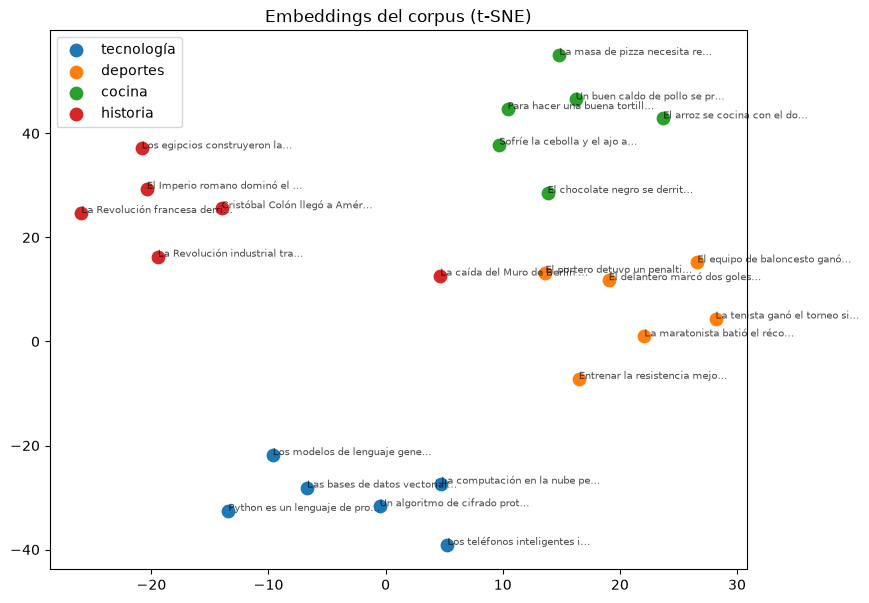

In [12]:
# Reducimos de 384 dimensiones a 2 (perplexity=5 porque tenemos pocas frases)
tsne = TSNE(n_components=2, perplexity=5, random_state=42)
coords = tsne.fit_transform(corpus_emb)  # 24 filas x 2 columnas (x, y)

plt.figure(figsize=(9, 7))

# Un color por tema: juntamos las coordenadas de las frases de cada tema
for tema in corpus_por_tema:
    xs = []
    ys = []
    for i in range(len(corpus)):
        if temas[i] == tema:
            xs.append(coords[i, 0])
            ys.append(coords[i, 1])
    plt.scatter(xs, ys, label=tema, s=80)

# Escribimos el inicio de cada frase junto a su punto
for i in range(len(corpus)):
    plt.annotate(corpus[i][:28] + "…", (coords[i, 0], coords[i, 1]), fontsize=7, alpha=0.7)

plt.legend()
plt.title("Embeddings del corpus (t-SNE)")
plt.show()